# NeRF in expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/main/examples/notebooks/nerf.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/main/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

A port of [JaxNeRF](https://github.com/google-research/google-research/tree/master/jaxnerf)
(Flax) to expex: [`examples/nerf/nerf.py`](../nerf/nerf.py), 138 lines of code against 334.
Everything is written for one ray (`S` samples along it, `F` more drawn from its coarse
weights); called on a batch of rays, it maps over them, so there is no batch axis to carry.
The MLP is written for one point and states its sizes (`MLP[P, V, W, C]`).

This notebook renders a few rays, shows what expex reads from the annotations, checks the port
against the original's saved outputs, and times it.

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "main"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO))
sys.path.insert(0, str(REPO / "examples" / "nerf"))
print("Python", sys.version.split()[0], "| examples from", REPO.name)

Python 3.14.6 | examples from vigilant-barnacle


In [2]:
import inspect
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
import nerf  # examples/nerf/nerf.py
from nerf import NeRF, Ray

print(inspect.getsource(nerf.NeRF.render))
print(inspect.getsource(nerf.composite))

    def render[S, F](self, ray: Ray, jitter: f32[S], u: f32[F], randomized: bool) -> tuple[Pixel, Pixel]:
        """One ray: S stratified samples through the coarse MLP, then S + F, F of them where its weights are, through the fine one."""
        assert S >= 3
        view = posenc(ray.viewdir, 0, self.deg_view)
        z = stratified(self.near, self.far, jitter, randomized, self.lindisp)
        coarse, weights = self.shade(self.coarse, ray, z, view)
        z = jnp.sort(jnp.concatenate([z, sample_pdf(0.5 * (z[1:] + z[:-1]), weights[1:-1], u)]))
        fine, _ = self.shade(self.fine, ray, z, view)
        return coarse, fine

@fn
def composite[S](
    rgb: f32[S, RGB], sigma: f32[S], z: f32[S], direction: f32[XYZ], white_bkgd: bool
) -> tuple[Pixel, f32[S]]:
    """Alpha compositing along the ray: the pixel, and each sample's weight in it."""
    eps = 1e-10
    dists = jnp.append(z[1:] - z[:-1], 1e10) * jnp.linalg.norm(direction)
    alpha = 1.0 - jnp.exp(-sigma * dists)
    trans

## The annotated signatures

Every typed function and method in the module, as expex reads it:

In [3]:
def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for report in expex.prove(nerf):
    print(signature(report.fn))

camera_ray(pose: f32[XYZ, 4], focal: float, x: f32[()], y: f32[()], w: int, h: int) -> Ray
posenc[X](x: f32[X], min_deg: int, max_deg: int) -> f32[X * (1 + 2 * (max_deg - min_deg))]
Dense.__call__(self: Dense, x: f32[I]) -> f32[O]
MLP.__call__(self: MLP, x: f32[P], view: f32[V]) -> tuple[f32[RGB], f32[()]]
stratified[S](near: float, far: float, u: f32[S], randomized: bool, lindisp: bool) -> f32[S]
composite[S](rgb: f32[S, RGB], sigma: f32[S], z: f32[S], direction: f32[XYZ], white_bkgd: bool) -> tuple[Pixel, f32[S]]
sample_pdf[N, F](bins: f32[N + 1], weights: f32[N], u: f32[F]) -> f32[F]
NeRF.create(cls, key: Key, depth: int, width: int, width_condition: int, skip_layer: int, **settings) -> NeRF
NeRF.__call__[B](self: NeRF, rays: Batch[Ray, B], rng_0: Key, rng_1: Key, randomized: bool) -> tuple[Batch[Pixel, B], Batch[Pixel, B]]
NeRF.render[S, F](self: NeRF, ray: Ray, jitter: f32[S], u: f32[F], randomized: bool) -> tuple[Pixel, Pixel]
NeRF.shade[T](self: NeRF, mlp: MLP[P, V, W, C], ray: 

`expex.debug.shapes` shows the shape of every line, for all sizes at once. Here the
hierarchical sampling: `F` depths drawn from the coarse weights on `N` bins.

In [4]:
print(expex.debug.shapes(nerf.sample_pdf))

sample_pdf[N, F](bins: f32[N + 1], weights: f32[N], u: f32[F]) -> f32[F]   [symbolic F, N]
  135 | @fn
  136 | def sample_pdf[N, F](bins: f32[N + 1], weights: f32[N], u: f32[F]) -> f32[F]:
  137 |     """F depths from the piecewise-constant density with `weights` on the N bins: the inverse CDF at u."""
  138 |     assert N >= 1
  139 |     total = weights.sum()                                                  # total: f32[()]
  140 |     padding = jnp.maximum(0.0, 1e-5 - total)  # no NaNs when every weight is (nearly) zero   # padding: f32[()]
  141 |     pdf = (weights + padding / N) / (total + padding)                      # pdf: f32[N]
  142 |     cdf = jnp.concatenate([jnp.zeros(1), jnp.minimum(1.0, jnp.cumsum(pdf[:-1])), jnp.ones(1)])   # cdf: f32[N + 1]
  143 |     above = jnp.searchsorted(cdf, u, side="right")  # the bin of u is [cdf[above - 1], cdf[above])   # above: i32[F]
  144 |     lo, hi = jnp.maximum(above - 1, 0), jnp.minimum(above, N)              # lo: i32[F], hi: i32[

## Run it

A small NeRF (8 layers of width 64) renders an 8 x 8 camera looking at the origin: 64 rays,
each with 64 coarse and 128 fine samples. Untrained, so the picture is noise; the point is the
shapes.

In [5]:
model = NeRF.create(jr.key(0), depth=8, width=64, width_condition=32)
pose = jnp.array([[1.0, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 4.0]])  # camera-to-world: at z = 4, looking down -z
ys, xs = jnp.meshgrid(jnp.arange(8.0), jnp.arange(8.0), indexing="ij")
rays = nerf.camera_ray(pose, 10.0, xs.ravel(), ys.ravel(), 8, 8)  # mapped over the 64 pixels
print("rays:", expex.show(rays))

render = jax.jit(NeRF.__call__, static_argnums=4)
coarse, fine = render(model, rays, jr.key(1), jr.key(2), True)
print("coarse:", expex.show(coarse))
print("fine opacity:\n", np.asarray(fine.acc.reshape(8, 8)).round(2))

rays: Ray(origin=f32[64, 3], direction=f32[64, 3], viewdir=f32[64, 3])


coarse: Pixel(rgb=f32[64, 3], disp=f32[64], acc=f32[64])
fine opacity:
 [[0.02 0.02 0.05 1.   0.02 0.01 0.02 0.06]
 [0.03 0.04 1.   1.   1.   1.   0.03 1.  ]
 [0.01 0.05 1.   1.   1.   1.   0.01 1.  ]
 [0.   0.03 0.   1.   1.   0.   0.   1.  ]
 [0.01 0.01 0.02 1.   1.   0.01 0.   1.  ]
 [0.02 0.07 0.06 0.03 1.   0.01 0.01 1.  ]
 [0.02 0.02 1.   1.   1.   0.   0.01 0.02]
 [0.01 0.02 0.01 0.   1.   1.   0.02 0.02]]


## What the annotations give

**Proofs** for every size, without data:

In [6]:
expex.prove(nerf)

ok    nerf.camera_ray
ok    nerf.posenc
ok    nerf.Dense.__call__
ok    nerf.MLP.__call__
ok    nerf.stratified
ok    nerf.composite
ok    nerf.sample_pdf
ok    nerf.NeRF.create
ok    nerf.NeRF.__call__
ok    nerf.NeRF.render
ok    nerf.NeRF.shade
ok    nerf.NeRF.loss

12 functions: 12 proved

**A summary** of the model. The MLPs' view-direction width `V` only appears inside `W + V`
(the colour branch takes the features and the encoded direction); expex solves for it once
`W` is known from another layer. The MLP, the compositing and a whole ray are costed as
formulas; `P` and `V` are numbers there, fixed by the encoding degrees (the `assert` in `shade`):

In [7]:
expex.summary(model)

NeRF   (P=63, V=27, W=64, C=32, L=4, RGB (= 3))
module            class                             params  formula                                                          bytes   flops  flops formula
─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
coarse            MLP[P=63, V=27, W=64, C=32]       44,516  2·W²·L + 2·P·W + 2·W² + 2·W·L + V·C + W·C + 4·W + 4·C + 4       178 kB    89 k  88964
  first           Dense[I=63, O=64]                  4,096  P·W + W                                                        16.4 kB  8.13 k  2·P·W + W
    kernel        f32[P, W]                          4,032  P·W                                                            16.1 kB
    bias          f32[W]                                64  W                                                                256 B
  before_skip[*]  Dense[I=64, O=64]            × 4   4,160  W² + W                    

In [8]:
print(expex.cost(nerf.MLP.__call__))
print(expex.cost(nerf.composite))
print(expex.cost(nerf.NeRF.render))

MLP.__call__   (sizes: P, V, W, C, L, RGB (= 3))
  flops        4·W²·L + 4·P·W + 4·W² + 4·W·L + 2·V·C + 2·W·C + 8·C + 7·W + 4
  parameters   2·W²·L + 2·P·W + 2·W² + 2·W·L + V·C + W·C + 4·W + 4·C + 4
  largest      f32[W + P] (P + W elements)
  note: L = len(self.before_skip, self.after_skip)
composite   (sizes: S, RGB (= 3), XYZ (= 3))
  flops        19·S + 13
  largest      f32[S] (S elements)
  note: white_bkgd=False (choose with white_bkgd=...)


NeRF.render   (sizes: S, F, W, C, L, RGB (= 3), XYZ (= 3))
  flops        8·S·W²·L + 4·F·W²·L + 8·S·W² + 8·S·W·L + 4·F·W² + 4·F·W·L + 4·S·W·C + 2·F·W·C + 518·S·W + 259·F·W + 124·S·C + 62·F·C + 323·S + 190·F + 64
  parameters   4·W²·L + 4·W² + 4·W·L + 2·W·C + 260·W + 62·C + 8
  largest      f32[S + F,W + 63] (S·W + F·W + 63·S + 63·F elements)
  note: randomized=False (choose with randomized=...)
  note: L = len(self.coarse.before_skip, self.coarse.after_skip, self.fine.before_skip, self.fine.after_skip)


**A diagram** of the MLP, drawn from the code (interactive when you run the notebook): the
layers before and after the skip connection are each one `lax.scan`, drawn as `× L`.

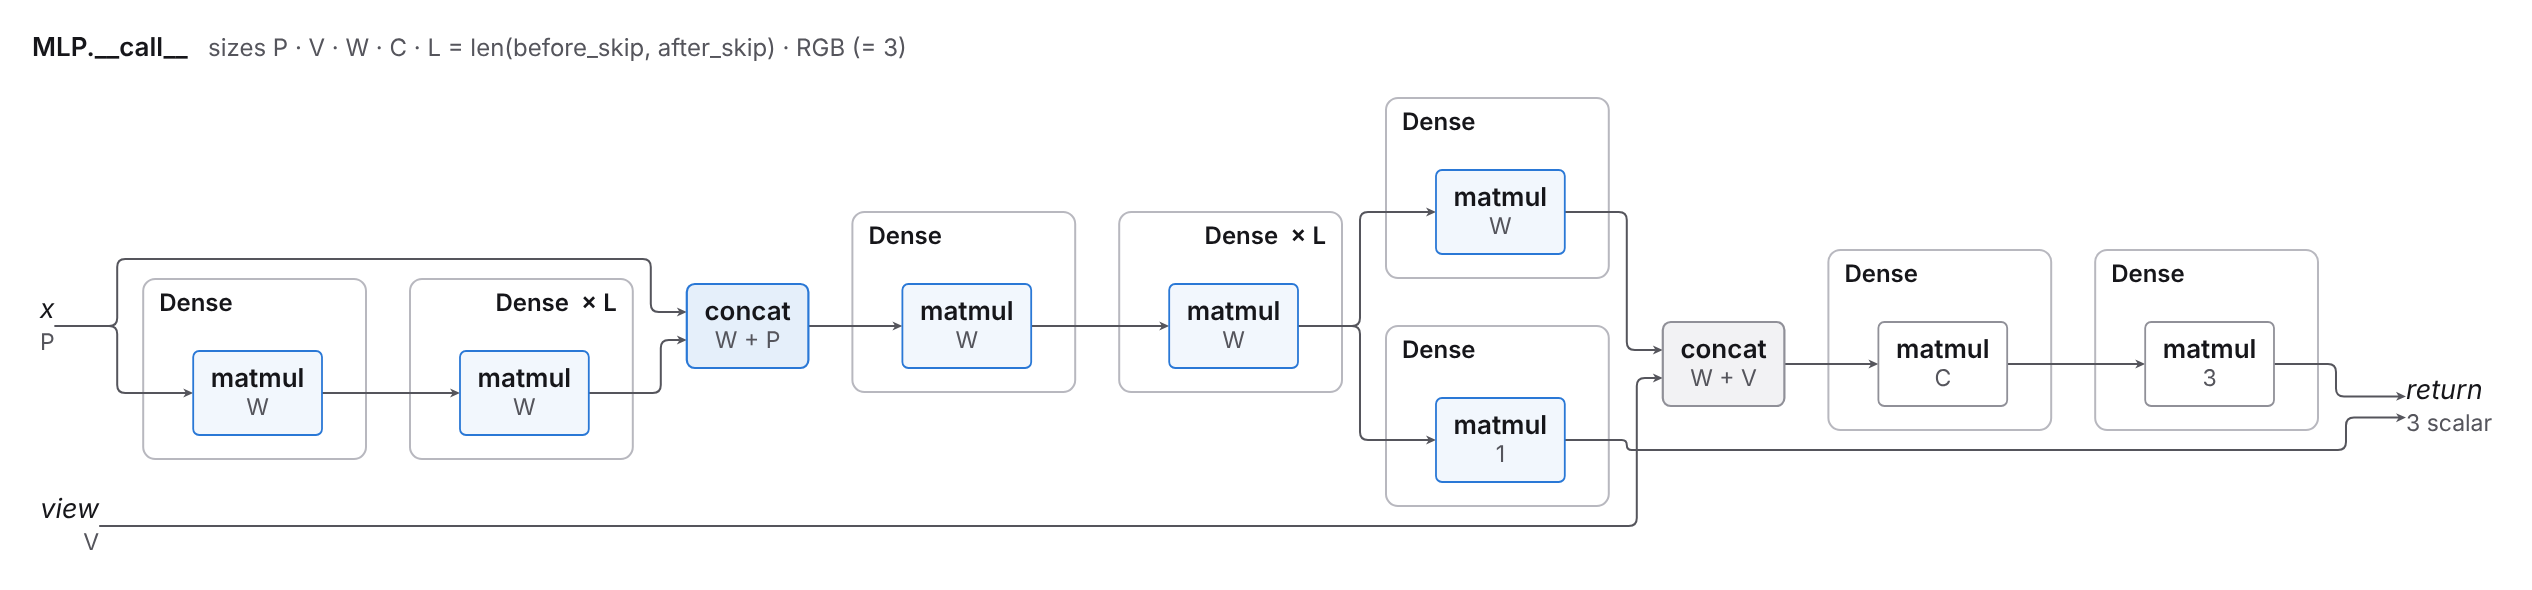

In [9]:
expex.diagram(nerf.MLP.__call__, depth=2)

**`expex.inspect`**: every tool in one page, for the coarse MLP on the 64 encoded sample
points of the first ray (it is written for one point, so it maps over them):

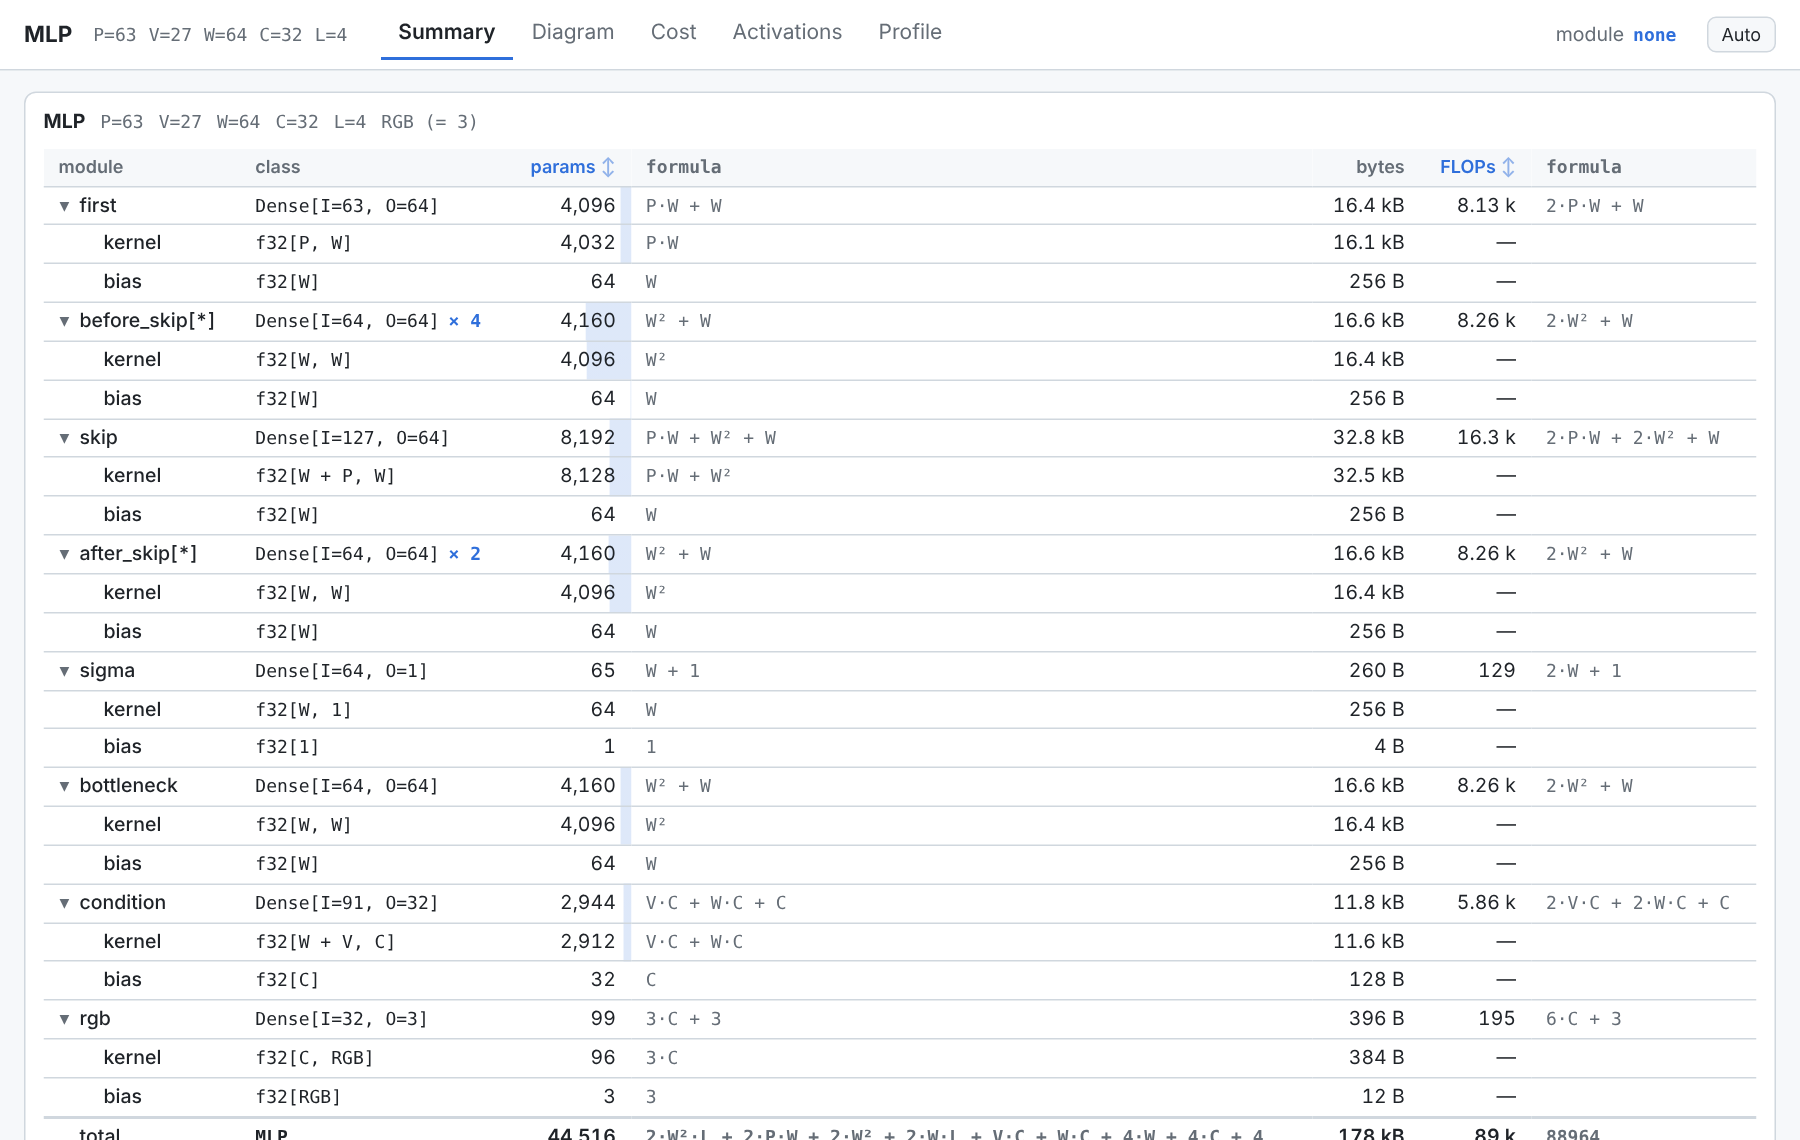

In [10]:
points = rays.origin[0] + jnp.outer(jnp.linspace(2.0, 6.0, 64), rays.direction[0])
encoded = nerf.posenc(points, 0, 10)  # mapped over the 64 points
view = nerf.posenc(rays.viewdir[0], 0, 4)
expex.inspect(model.coarse, encoded, jnp.broadcast_to(view, (64, view.shape[0])))

## A shape error

Rays are `Ray(origin: f32[XYZ], ...)`, with `XYZ` a size fixed at 3. Rays in 2D are refused,
with the field that disagrees:

In [11]:
flat = Ray(rays.origin[:, :2], rays.direction[:, :2], rays.viewdir[:, :2])
try:
    model(flat, jr.key(1), jr.key(2), True)
except expex.ShapeError as e:
    error = e
error

ShapeError: NeRF.__call__(): argument `rays` does not match its annotation.

    declared  rays.origin: f32[B, XYZ]
    received               f32[64, 2]

    axis 1 should be XYZ, which is fixed at 3, but is 2.

    __call__[B](self: NeRF, rays: Batch[Ray, B], rng_0: Key, rng_1: Key, randomized: bool) -> tuple[Batch[Pixel, B], Batch[Pixel, B]]
    defined at examples/nerf/nerf.py:179
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


## Activations and gradients, call by call

`expex.debug.watch` of the training loss on 16 of the rays, with the untrained model's colours as
targets plus noise:

In [12]:
pixels = jnp.clip(fine.rgb + 0.1 * jr.normal(jr.key(3), fine.rgb.shape), 0, 1)
few = jax.tree.map(lambda x: x[:16], rays)  # 16 of the rays
watch = expex.debug.watch(lambda m: m.loss(few, pixels[:16], jr.key(1), jr.key(2)), model)
print(f"{len(watch.rows)} calls, {len(watch.flagged)} flagged")
watch

38 calls, 0 flagged


watch <lambda>: loss 0.116726, 38 calls, 0 flagged  (grad_ratio=100.0, growth=10.0)
                                                                                                                 ────────────────output────────────────  ───────────────d loss / d output────────────────
  call                                      shape                                                            ×n      mean    std  |max|    rms  nan/inf       mean       std     |max|       rms  nan/inf  flags
  NeRF.loss                                 f32                                                               1     0.117      0  0.117  0.117                   1         0         1         1
    NeRF.__call__                           (f32[16, 3], f32[16], f32[16], f32[16, 3], f32[16], f32[16])      1      0.58  0.331      1  0.667            -0.00372   0.00936     0.024    0.0101
      NeRF.render                           (f32[3], f32, f32, f32[3], f32, f32)                             16      0.

## Against the original

`tests/data/nerf_reference.npz` holds the parameters of a small JaxNeRF model built by the
unmodified original, the coarse and fine pixels it renders for 64 rays (random and fixed
sampling), and its training loss with gradients. `compare.py` loads those parameters into the
port and measures the largest differences:

In [13]:
import compare  # examples/nerf/compare.py

reference = dict(np.load(REPO / "tests" / "data" / "nerf_reference.npz"))
for name, diff in compare.compare(reference).items():
    print(f"{name:24} {diff:.3g}")

rgb_c (random)           5.96e-08
disp_c (random)          0
acc_c (random)           0
rgb (random)             2.38e-07
disp (random)            5.96e-08
acc (random)             1.19e-07
rgb_c (fixed)            5.96e-08
disp_c (fixed)           5.96e-08
acc_c (fixed)            0
rgb (fixed)              1.79e-07
disp (fixed)             2.98e-08
acc (fixed)              1.19e-07
loss                     0
gradients (relative)     1.64e-06
camera rays              1.19e-07


## Speed

Compiled rendering and gradients of the 64 rays. Timings depend on the machine, so compare
them only with each other. The repository's [benchmarks/](../../benchmarks/) compare the port
with the original on CPU (best of 25 rounds, median in brackets): rendering slightly slower,
0.96x (0.93x); gradients 1.08x (1.02x).

In [14]:
def bench(f, *args, n=10):
    """Median seconds per call, after a first call that compiles."""
    jax.block_until_ready(f(*args))
    times = []
    for _ in range(n):
        start = time.perf_counter()
        jax.block_until_ready(f(*args))
        times.append(time.perf_counter() - start)
    return float(np.median(times))


grads = jax.jit(jax.grad(NeRF.loss))
print(f"render 64 rays    {bench(render, model, rays, jr.key(1), jr.key(2), True) * 1e3:7.2f} ms")
print(f"gradients 64 rays {bench(grads, model, rays, pixels, jr.key(1), jr.key(2)) * 1e3:7.2f} ms")

render 64 rays      12.71 ms


gradients 64 rays   46.05 ms
